# ARTI-450: Project 1 - Multilayered Perceptrons
Dylan Dyke and Eddie Kaufuma-Henry

## Import Statements

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visualizations
import matplotlib.pyplot as plt
import seaborn as sns

# Handling imbalanced data using SMOTE
from imblearn.over_sampling import SMOTENC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import MinMaxScaler

# TensorFlow and Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.layers import Dense

# Traditional Machine Learning imports

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Hyperparameter tuning
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)

from scipy.stats import loguniform
import time

## Exploratory Data Analysis

In [2]:
## Check where Jupyter is looking for the CSV, make sure our CSV is there
import os
print(os.getcwd())

C:\Users\DylanFerris\Contacts\ARTI-450and405


In [3]:
df = pd.read_csv("Loan_default.csv")

In [4]:
df.sample(10)

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
128735,I8OPSC75VR,56,124565,65082,402,25,3,3.76,24,0.64,Bachelor's,Self-employed,Married,Yes,No,Other,Yes,0
129554,PN98UOIEXA,64,128879,106135,376,69,1,17.21,12,0.36,Master's,Self-employed,Divorced,Yes,Yes,Other,Yes,0
185612,FGFGE85B5O,52,68656,146427,515,26,4,22.03,36,0.32,PhD,Part-time,Single,No,Yes,Auto,No,0
47383,6JBBTP80FE,40,138157,203701,646,39,4,2.44,48,0.12,PhD,Part-time,Divorced,No,No,Home,No,0
146877,RRI4W7JQXL,54,140153,199561,797,26,3,19.57,48,0.47,High School,Full-time,Married,No,Yes,Business,Yes,0
200725,SIT6FR0RI2,41,124872,79343,688,0,2,17.06,48,0.75,High School,Part-time,Single,No,Yes,Business,Yes,1
109414,EO9L61NA2D,54,120037,178558,514,32,2,20.22,24,0.23,Bachelor's,Part-time,Married,Yes,No,Auto,Yes,0
154680,CEW6I9UI5R,67,67688,216558,742,60,4,9.51,60,0.46,Bachelor's,Full-time,Divorced,Yes,No,Business,Yes,0
205705,OZBMV3TQHB,47,23098,94129,625,48,3,20.53,24,0.49,Bachelor's,Part-time,Married,No,Yes,Other,Yes,0
168795,55GLQEUGHR,37,32678,227557,603,118,1,16.57,48,0.30,Master's,Self-employed,Single,No,No,Business,No,0


1. Dataset dimensions and feature types.
2. Descriptive statistics.
3. Missing-value analysis.
4. Duplicate-record analysis.
5. Target variable distribution.
6. Appropriate visualizations of important features.
7. Identification of potential outliers.

### Dataset dimensions and feature types.

In [5]:
#data dimensions & Feature Types
# Data dimensions: number of rows and columns
print("Data dimensions:")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Data type of each column
print("\nFeature types:")
print(df.dtypes)

Data dimensions:
Number of rows: 255347
Number of columns: 18

Feature types:
LoanID                str
Age                 int64
Income              int64
LoanAmount          int64
CreditScore         int64
MonthsEmployed      int64
NumCreditLines      int64
InterestRate      float64
LoanTerm            int64
DTIRatio          float64
Education             str
EmploymentType        str
MaritalStatus         str
HasMortgage           str
HasDependents         str
LoanPurpose           str
HasCoSigner           str
Default             int64
dtype: object


### Descriptive statistics.

In [6]:
df.describe()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


### Missing Value Analysis

In [7]:
df.isnull().sum()

LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64

### Duplicate Record Analysis

In [8]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


### Target Variable Analysis

In [9]:
print(df["Default"].value_counts())
print("\nPercentage:")
print(df["Default"].value_counts(normalize=True) * 100)

Default
0    225694
1     29653
Name: count, dtype: int64

Percentage:
Default
0    88.387175
1    11.612825
Name: proportion, dtype: float64


### Appropiate Visuals of Important Features

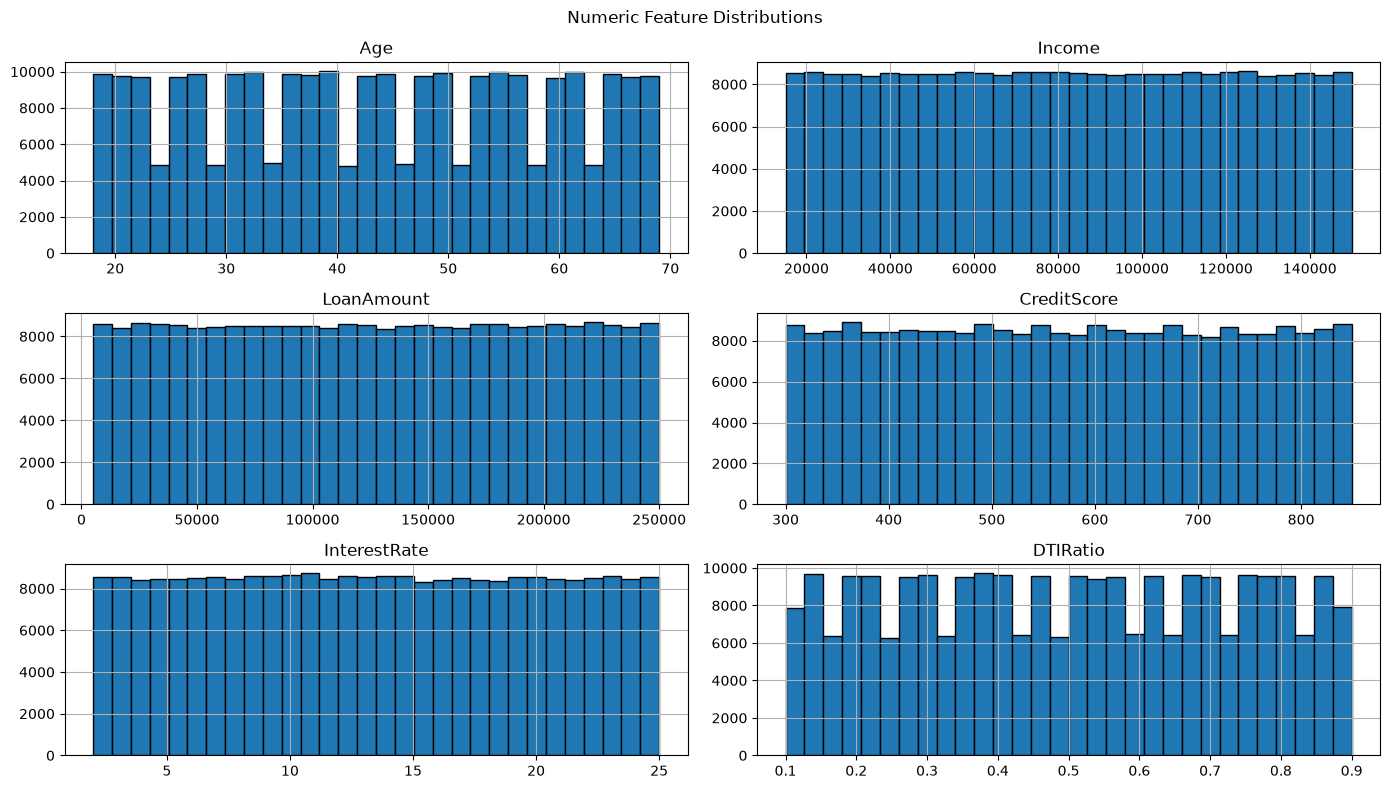

In [10]:
numeric_features = [
    "Age", "Income", "LoanAmount",
    "CreditScore", "InterestRate", "DTIRatio"
]

df[numeric_features].hist(
    figsize=(14, 8),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Numeric Feature Distributions")
plt.tight_layout()
plt.show()

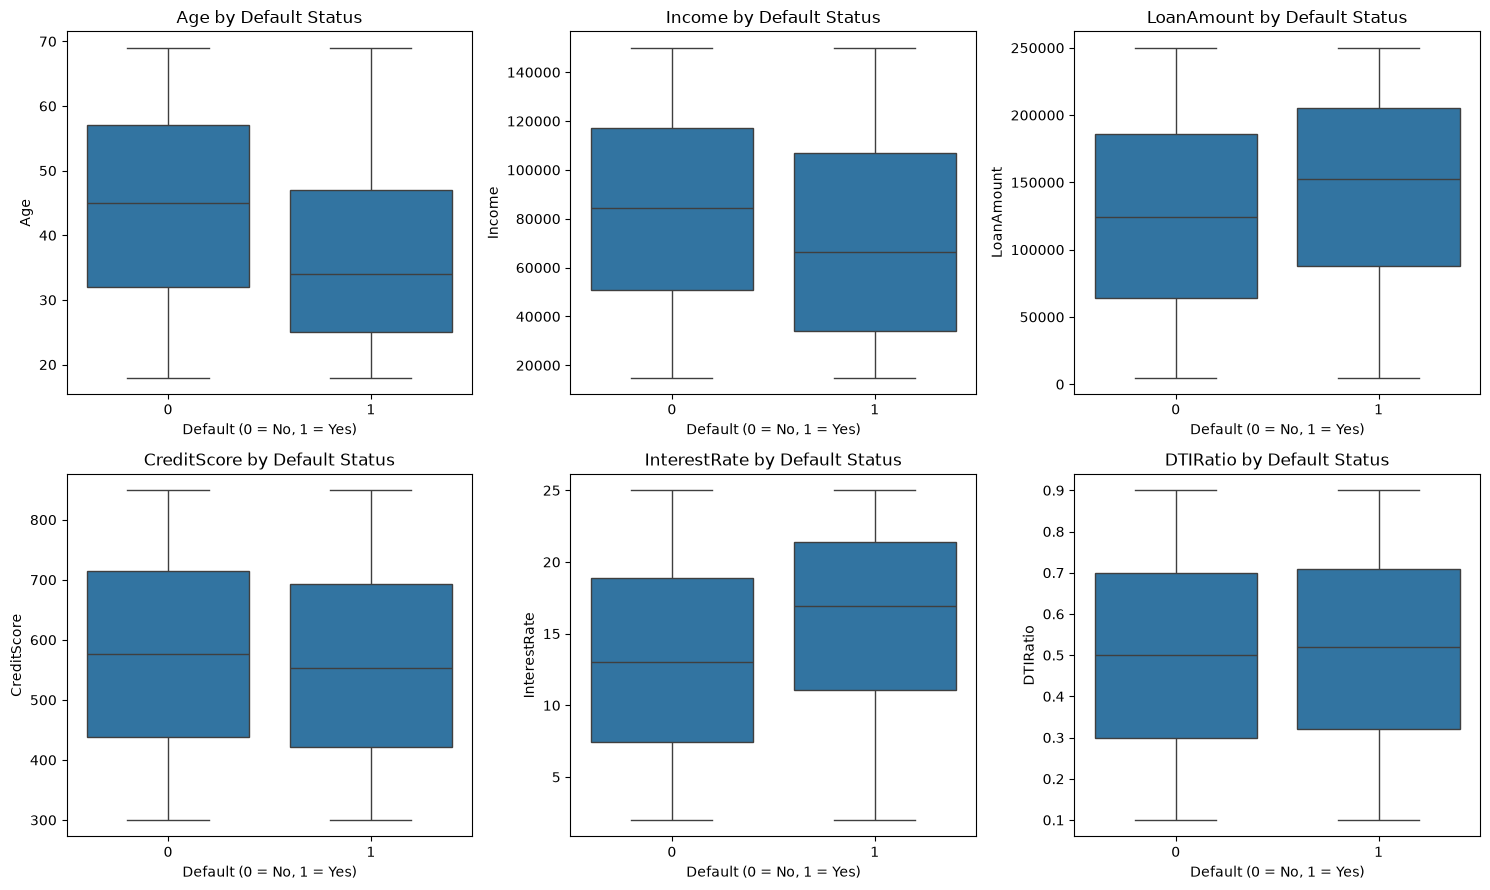

In [11]:
#Numeric features compared to target

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for feature, ax in zip(numeric_features, axes.flatten()):
    sns.boxplot(data=df, x="Default", y=feature, ax=ax)
    ax.set_title(f"{feature} by Default Status")
    ax.set_xlabel("Default (0 = No, 1 = Yes)")

plt.tight_layout()
plt.show()

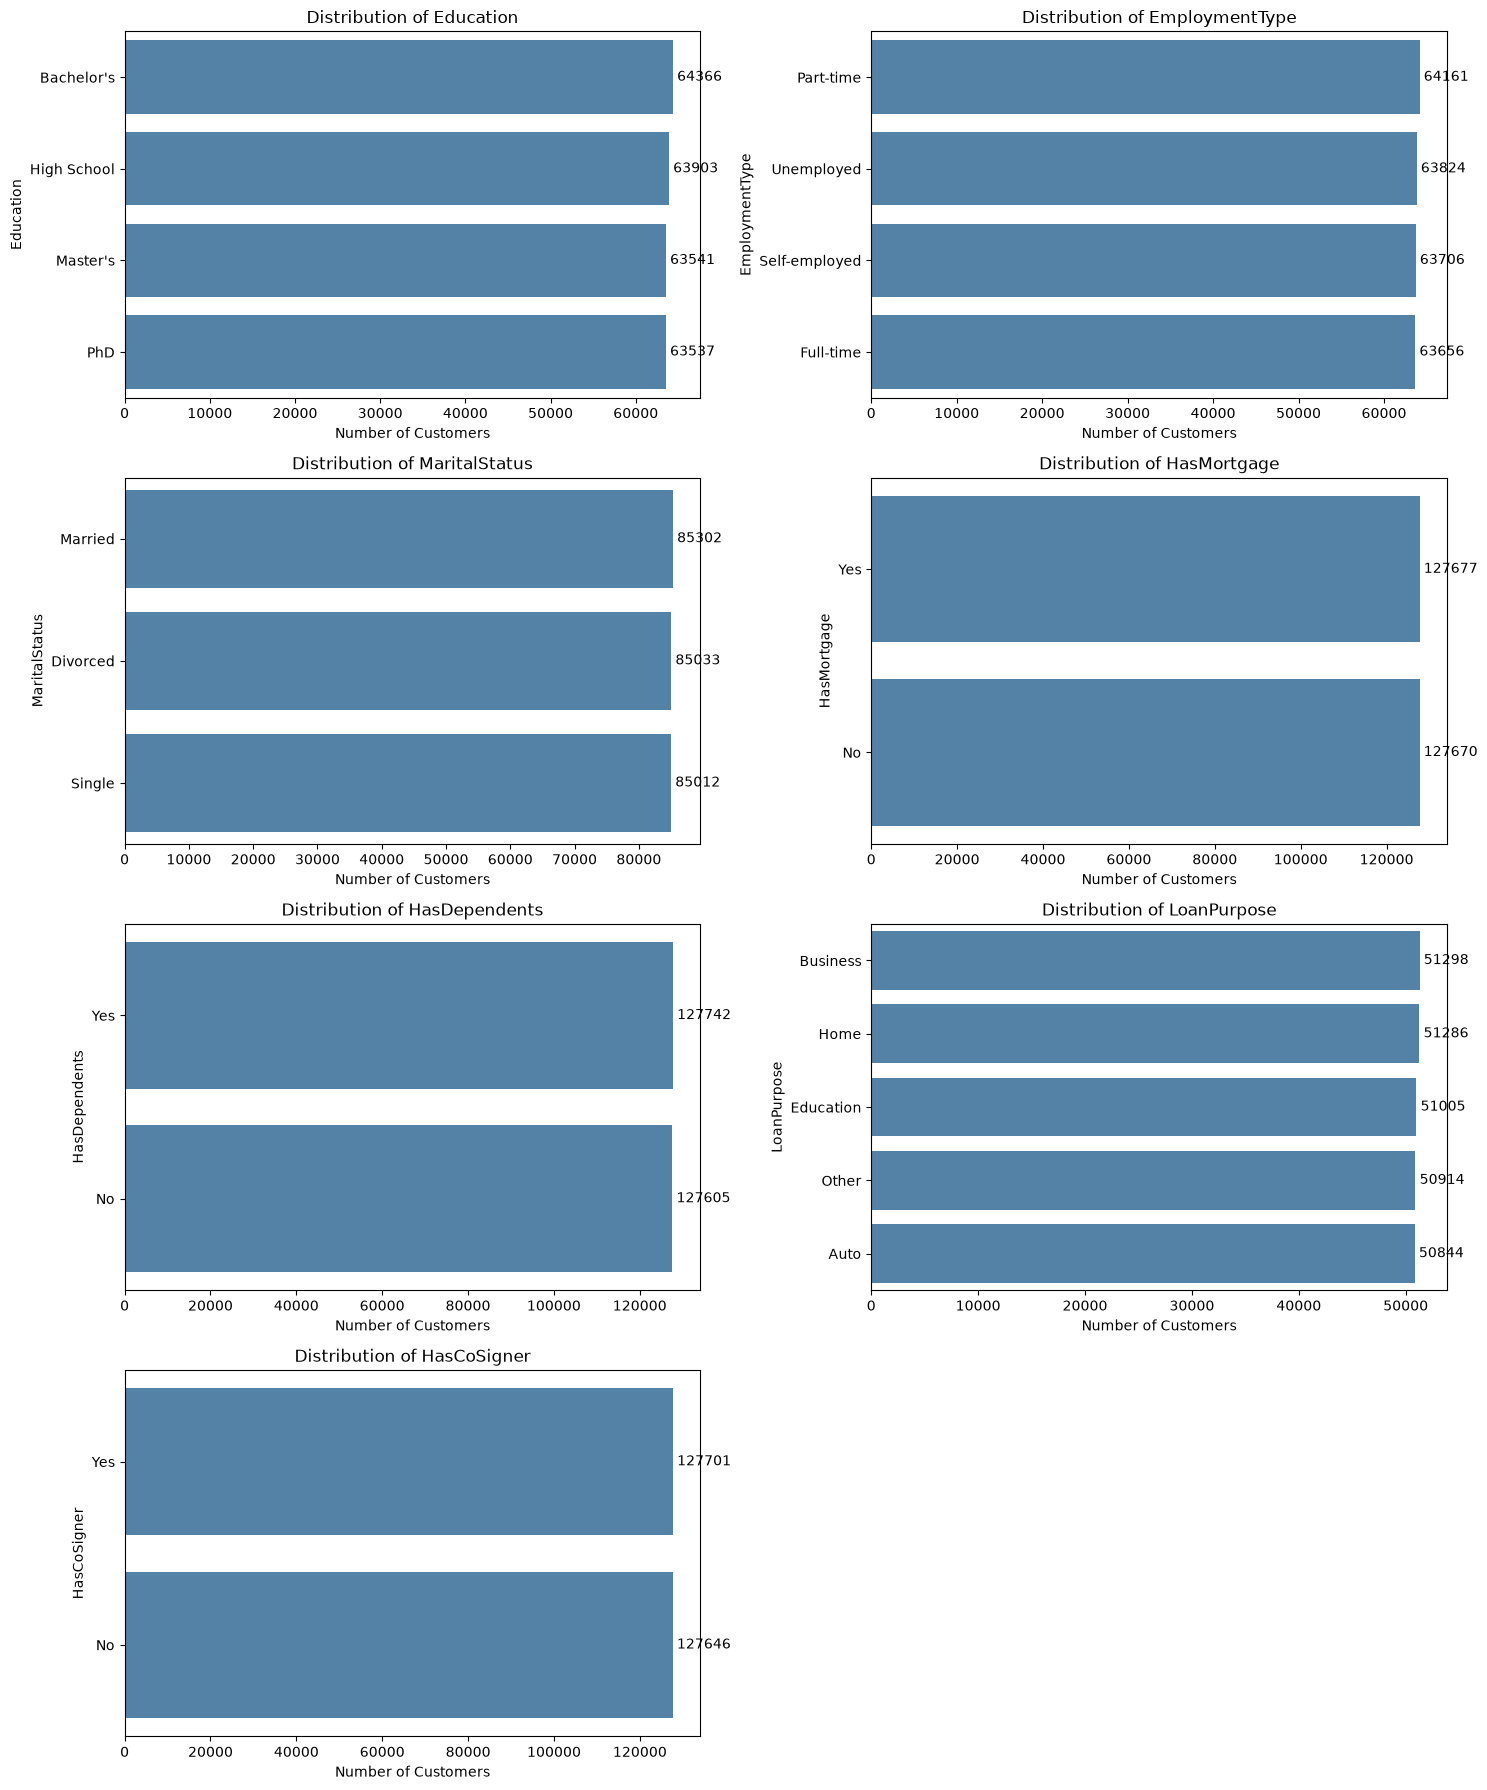

In [12]:
categorical_features = [
    "Education", "EmploymentType", "MaritalStatus",
    "HasMortgage", "HasDependents", "LoanPurpose", "HasCoSigner"
]

fig, axes = plt.subplots(4, 2, figsize=(15, 18))

for feature, ax in zip(categorical_features, axes.flatten()):
    sns.countplot(
        data=df,
        y=feature,
        order=df[feature].value_counts().index,
        ax=ax,
        color="steelblue"
    )
    ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel("Number of Customers")
    ax.set_ylabel(feature)

# Hide the unused eighth subplot
axes.flatten()[-1].set_visible(False)

plt.tight_layout()
plt.show()

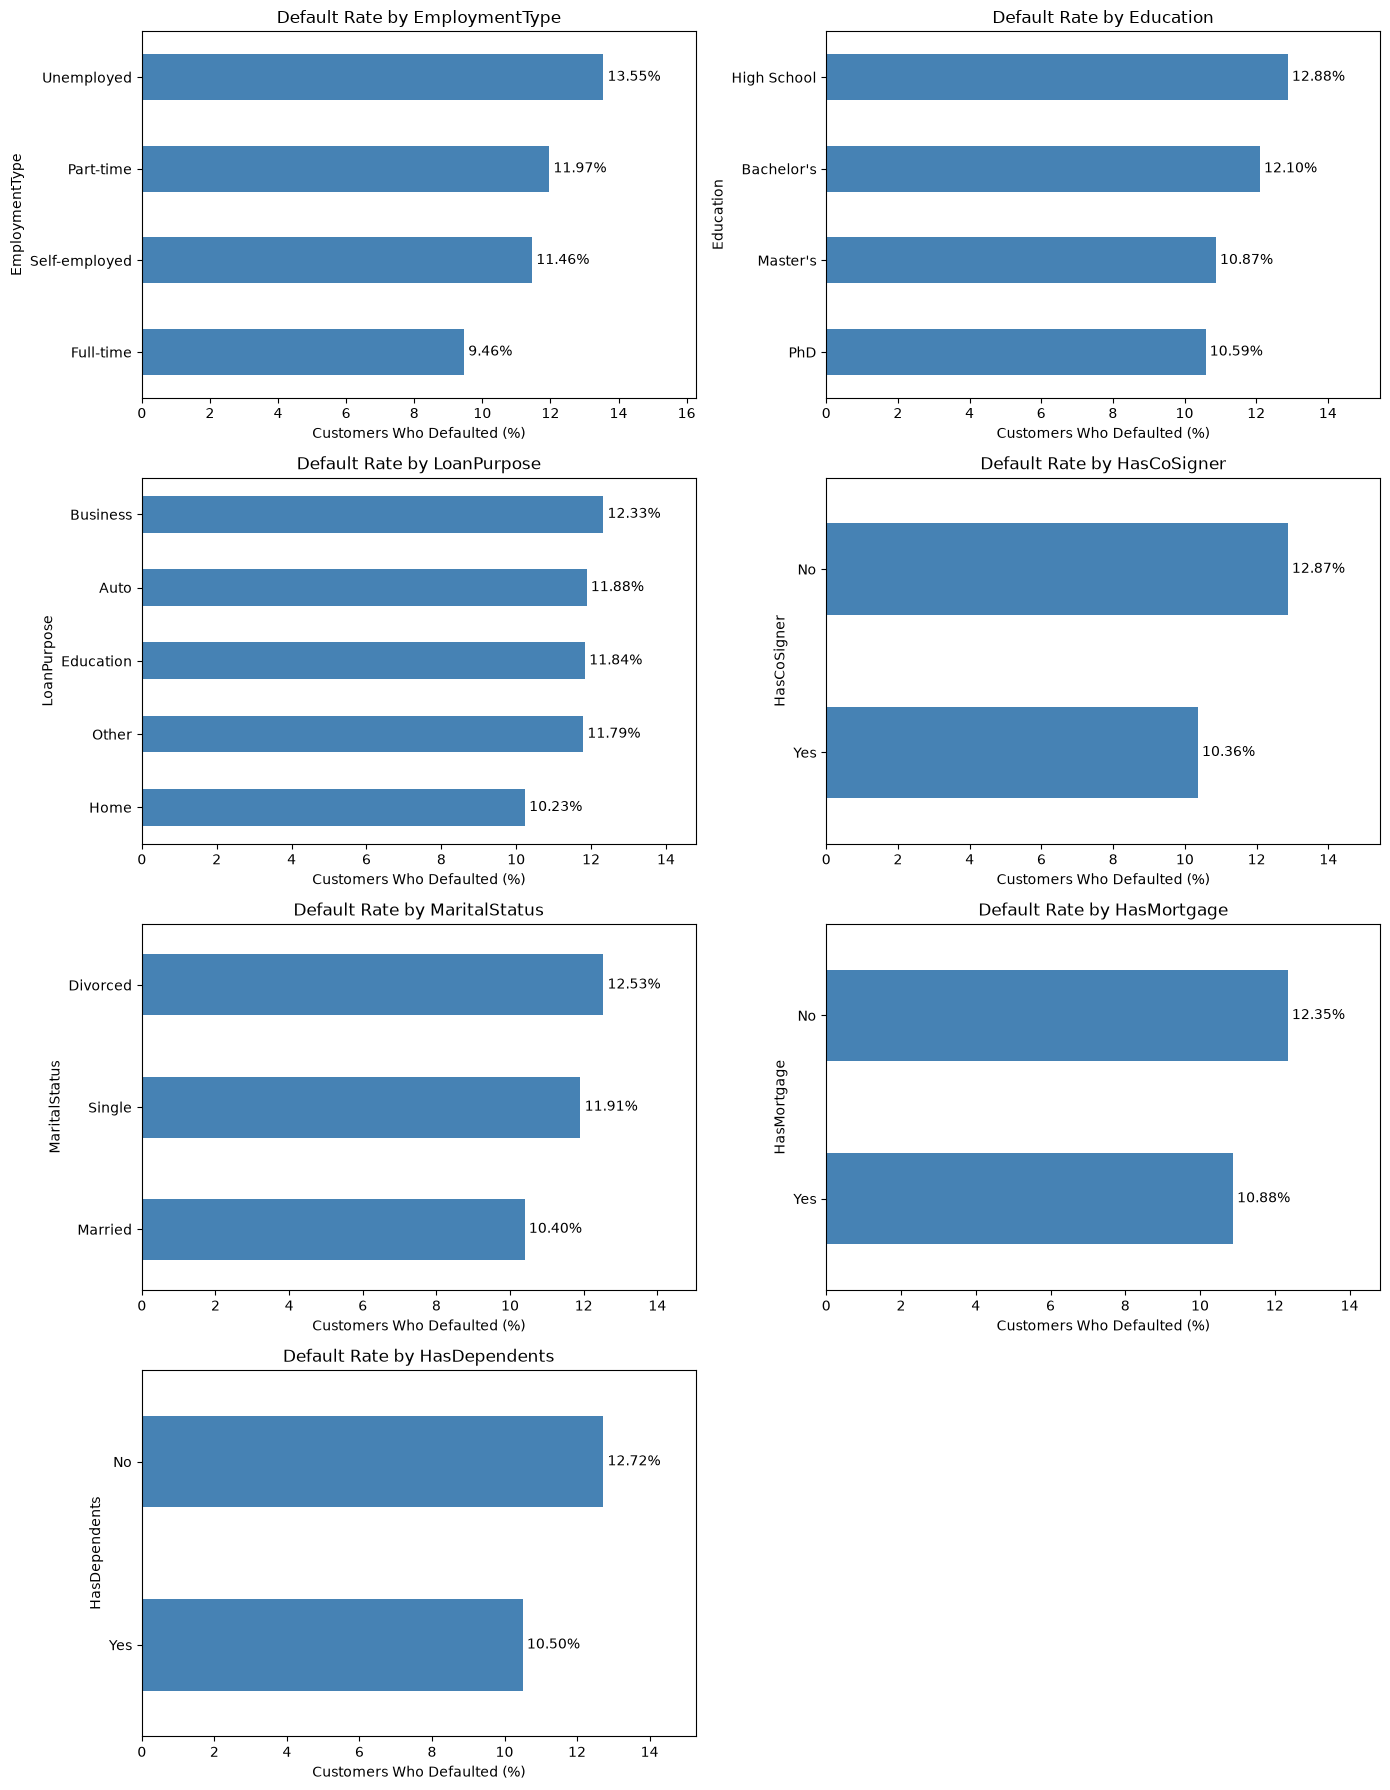

In [13]:
#categorical features compared to target
categorical_features = [
    "EmploymentType", "Education", "LoanPurpose", "HasCoSigner",
    "MaritalStatus", "HasMortgage", "HasDependents"
]

fig, axes = plt.subplots(4, 2, figsize=(14, 18))

for feature, ax in zip(categorical_features, axes.flatten()):
    default_rates = (
        df.groupby(feature)["Default"]
        .mean()
        .mul(100)
        .sort_values()
    )

    default_rates.plot(kind="barh", ax=ax, color="steelblue")
    ax.set_title(f"Default Rate by {feature}")
    ax.set_xlabel("Customers Who Defaulted (%)")
    ax.set_ylabel(feature)

    ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
    ax.set_xlim(0, default_rates.max() * 1.2)

# Hide the unused eighth subplot
axes.flatten()[-1].set_visible(False)

plt.tight_layout()
plt.show()

### Identify Outliers

In [14]:
# Numeric features
numeric_features = df.select_dtypes(include="number").columns.drop("Default")

outlier_summary = []

for feature in numeric_features:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    )

    outlier_summary.append({
        "Feature": feature,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outliers.sum(),
        "Outlier Percentage": outliers.mean() * 100
    })

# Display results
outlier_results = pd.DataFrame(outlier_summary)
outlier_results.round(2)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Age,-6.50,93.50,0,0.0
1,Income,-52264.75,217309.25,0,0.0
2,LoanAmount,-118087.50,373228.50,0,0.0
3,CreditScore,24.50,1124.50,0,0.0
4,MonthsEmployed,-60.00,180.00,0,0.0
5,NumCreditLines,0.50,4.50,0,0.0
6,InterestRate,-9.45,36.47,0,0.0
7,LoanTerm,-12.00,84.00,0,0.0
8,DTIRatio,-0.30,1.30,0,0.0


## Data Cleaning and Preprocessing

1. Handling missing values.
2. Removing duplicate observations where appropriate.
3. Addressing invalid or inconsistent data.
4. Encoding categorical variables.
5. Normalizing or standardizing numerical features.
6. Handling class imbalance, if applicable.
7. Splitting the dataset into training, validation, and testing sets.

In [15]:
# Separate features and target
X = df.drop(columns=["LoanID", "Default"]).copy()
y = df["Default"].copy()

# Map Yes/No to 1/0
binary_columns = ["HasMortgage", "HasDependents", "HasCoSigner"]

for column in binary_columns:
    X[column] = X[column].map({"No": 0, "Yes": 1})

### Splitting data

In [16]:
# Define column groups
numeric_columns = [
    "Age", "Income", "LoanAmount", "CreditScore",
    "MonthsEmployed", "NumCreditLines", "InterestRate",
    "LoanTerm", "DTIRatio"
]

categorical_columns = [
    "Education", "EmploymentType", "MaritalStatus", "LoanPurpose"
]

# SMOTENC must also recognize the binary columns as categorical
all_categorical_columns = categorical_columns + binary_columns

# 70% training, 15% validation, 15% testing
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

### Normalizing or standardizing numerical features

In [17]:
scaler = MinMaxScaler()

# Learn scaling from training data only
X_train[numeric_columns] = scaler.fit_transform(
    X_train[numeric_columns]
)

# Apply the same scaling to validation and test data
X_val[numeric_columns] = scaler.transform(X_val[numeric_columns])
X_test[numeric_columns] = scaler.transform(X_test[numeric_columns])

### Handle Class Imbalance.

In [18]:
print("Before SMOTENC:")
print(y_train.value_counts())

smote_nc = SMOTENC(
    categorical_features=all_categorical_columns,
    random_state=42
)

X_train_balanced, y_train_balanced = smote_nc.fit_resample(
    X_train, y_train
)

print("\nAfter SMOTENC:")
print(y_train_balanced.value_counts())

Before SMOTENC:
Default
0    157985
1     20757
Name: count, dtype: int64

After SMOTENC:
Default
0    157985
1    157985
Name: count, dtype: int64


### Encoding Categorical Values

In [19]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoder.fit(X_train[categorical_columns])

encoded_names = encoder.get_feature_names_out(categorical_columns)

def encode_features(data):
    encoded = encoder.transform(data[categorical_columns])

    encoded_df = pd.DataFrame(
        encoded,
        columns=encoded_names,
        index=data.index
    )

    return pd.concat(
        [data.drop(columns=categorical_columns), encoded_df],
        axis=1
    )

X_train_balanced = encode_features(X_train_balanced)
X_train = encode_features(X_train)
X_val = encode_features(X_val)
X_test = encode_features(X_test)

print("Original training dimensions:", X_train.shape)
print("Balanced training dimensions:", X_train_balanced.shape)
print("Validation dimensions:", X_val.shape)
print("Test dimensions:", X_test.shape)

X_train_balanced.head()

Original training dimensions: (178742, 28)
Balanced training dimensions: (315970, 28)
Validation dimensions: (38302, 28)
Test dimensions: (38303, 28)


,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,HasMortgage,...,EmploymentType_Self-employed,EmploymentType_Unemployed,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single,LoanPurpose_Auto,LoanPurpose_Business,LoanPurpose_Education,LoanPurpose_Home,LoanPurpose_Other
0,0.058824,0.976741,0.596443,0.981785,0.882353,0.333333,0.594348,0.25,0.7250,0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.352941,0.775828,0.261524,0.032787,0.773109,0.000000,0.025217,0.75,0.8625,0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.607843,0.820176,0.986106,0.901639,0.361345,1.000000,0.736522,0.00,0.9125,0,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3,0.333333,0.724287,0.731791,0.877960,0.067227,1.000000,0.277826,0.25,0.3250,1,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.627451,0.393670,0.387495,0.083789,0.974790,0.333333,0.657391,1.00,0.5125,1,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


## Feature Selection

- Identify the selected features: Age, Income, Loan Amount, Interestrate, CreditScore, EnrollmentType, HasCoSigner, Education, and HasDependents

- Explain the feature selection technique: We manually engineered these features based on EDA using graphs comparing them with loan default and chose features that may help explain a customer’s ability to repay. This approach uses our understanding of the data.

-  Justify why the selected features are relevant:  Income, LoanAmount, and DTIRatio describe a customer’s financial situation and debt burden. CreditScore provides information about credit history. EmploymentType and MonthsEmployed describe employment status and income stability. InterestRate affects borrowing costs, while HasCoSigner shows whether another person shares responsibility for repayment (better odds of non-default). Age may also capture differences between borrowers. These features may help predict default, but comparing model results will help determine whether this smaller selection improves performance.

- Compare model performance using all eligible features versus the selected features

## MLP Development

Model Specifications

1. Input Features:
2. Hidden Layers:
3. Number of Neurons in Each Layer:
4. Activation Functions:
5. Loss Function:
6. Optimizer:
7. Learning rate:
8. Batch size:
9. Number of Training Epochs:

### Inital Set Up

In [20]:
## Selected Data and All Eligible Data Split
# Define the selected original features
selected_features = [
    "Age",
    "Income",
    "LoanAmount",
    "InterestRate",
    "CreditScore",
    "HasCoSigner",
    "HasDependents"
]

# Include all one-hot encoded columns belonging to
# Education and EmploymentType
selected_feature_columns = [
    column for column in X_train_balanced.columns
    if (
        column in selected_features
        or column.startswith("Education_")
        or column.startswith("EmploymentType_")
    )
]

# Create selected-feature datasets
X_train_selected = X_train_balanced[selected_feature_columns]
X_val_selected = X_val[selected_feature_columns]
X_test_selected = X_test[selected_feature_columns]

# Display selected features
print("Selected MLP input features:")
print(selected_feature_columns)

print("\nNumber of selected input features:",
      len(selected_feature_columns))

print("\nTraining dimensions:", X_train_selected.shape)
print("Validation dimensions:", X_val_selected.shape)
print("Testing dimensions:", X_test_selected.shape)

Selected MLP input features:
['Age', 'Income', 'LoanAmount', 'CreditScore', 'InterestRate', 'HasDependents', 'HasCoSigner', "Education_Bachelor's", 'Education_High School', "Education_Master's", 'Education_PhD', 'EmploymentType_Full-time', 'EmploymentType_Part-time', 'EmploymentType_Self-employed', 'EmploymentType_Unemployed']

Number of selected input features: 15

Training dimensions: (315970, 15)
Validation dimensions: (38302, 15)
Testing dimensions: (38303, 15)


In [21]:
## Reproducibility
tf.keras.utils.set_random_seed(42)

In [22]:
## Function to develop MLP

def create_mlp(input_features):

    model = keras.Sequential([
        # Input layer
        layers.Input(shape=(input_features,)),

        # Hidden layer 1
        layers.Dense(64, activation="relu"),

        # Hidden layer 2
        layers.Dense(32, activation="relu"),

        # Output layer
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

### Baseline MLP Model with Selected Features

In [23]:
## Develop baseline model using selected features

# Create baseline MLP
baseline_mlp = create_mlp(
    input_features=X_train_selected.shape[1]
)

# Display model architecture
baseline_mlp.summary()

# Early stopping to prevent unnecessary training
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train baseline MLP
baseline_history = baseline_mlp.fit(
    X_train_selected.to_numpy(dtype=np.float32),
    y_train_balanced.to_numpy(dtype=np.float32),

    validation_data=(
        X_val_selected.to_numpy(dtype=np.float32),
        y_val.to_numpy(dtype=np.float32)
    ),

    epochs=50,
    batch_size=256,
    callbacks=[early_stopping],
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,137 (12.25 KB)

 Trainable params: 3,137 (12.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
1235/1235 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.6754 - loss: 0.5998 - val_accuracy: 0.6453 - val_loss: 0.6276
Epoch 2/50
1235/1235 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6841 - loss: 0.5897 - val_accuracy: 0.6482 - val_loss: 0.6207
Epoch 3/50
1235/1235 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6866 - loss: 0.5871 - val_accuracy: 0.6535 - val_loss: 0.6142
Epoch 4/50
1235/1235 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6875 - loss: 0.5856 - val_accuracy: 0.6540 - val_loss: 0.6130
Epoch 5/50
1235/1235 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6883 - loss: 0.5846 - val_accuracy: 0.6532 - val_loss: 0.6123
Epoch 6/50
1235/1235 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6888 - loss: 0.5837 - val_accuracy: 0.6529 - val_loss: 0.6130
Epoch 7/50
1235/1235 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.6894 - loss: 0.5830 - val_accuracy: 0.6500 - val_loss: 0.6141
Epoch 8/50
1235/1235 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6898 - loss: 0.5822 - 

In [24]:
## Evaluate model

## Generate predictions
baseline_predictions = baseline_mlp.predict(
    X_test_selected.to_numpy(dtype=np.float32)
)

## Convert probabilities into binary predictions
baseline_predictions = (
    baseline_predictions >= 0.5
).astype(int).flatten()

## Calculate evaluation metrics
baseline_accuracy = accuracy_score(
    y_test, baseline_predictions
)

baseline_precision = precision_score(
    y_test, baseline_predictions,
    zero_division=0
)

baseline_recall = recall_score(
    y_test, baseline_predictions,
    zero_division=0
)

baseline_f1 = f1_score(
    y_test, baseline_predictions,
    zero_division=0
)

## Display results
print("Baseline MLP - Selected Features")
print("--------------------------------")
print("Accuracy:", baseline_accuracy)
print("Precision:", baseline_precision)
print("Recall:", baseline_recall)
print("F1-Score:", baseline_f1)

print("\nClassification Report:")
print(classification_report(
    y_test,
    baseline_predictions,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    baseline_predictions
))

1197/1197 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
Baseline MLP - Selected Features
--------------------------------
Accuracy: 0.6500796282275539
Precision: 0.2046698766572126
Recall: 0.6976169064748201
F1-Score: 0.3164873272476924

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.64      0.76     33855
           1       0.20      0.70      0.32      4448

    accuracy                           0.65     38303
   macro avg       0.57      0.67      0.54     38303
weighted avg       0.86      0.65      0.71     38303


Confusion Matrix:
[[21797 12058]
 [ 1345  3103]]


In [25]:
## Model Specifications

print("BASELINE MLP (SELECTED FEATURES)")
print("--------------------------------")
print("1. Input Features:", X_train_selected.shape[1])
print("2. Hidden Layers:", len([layer for layer in baseline_mlp.layers if isinstance(layer, Dense)]) - 1)
print("3. Neurons in Each Layer: 64, 32")
print("4. Activation Functions: ReLU (hidden layers), Sigmoid (output)")
print("5. Loss Function: Binary Crossentropy")
print("6. Optimizer: Adam")
print("7. Learning Rate: 0.001")
print("8. Batch Size: 256")
print("9. Training Epochs:", len(baseline_history.history["loss"]))

BASELINE MLP (SELECTED FEATURES)
--------------------------------
1. Input Features: 15
2. Hidden Layers: 2
3. Neurons in Each Layer: 64, 32
4. Activation Functions: ReLU (hidden layers), Sigmoid (output)
5. Loss Function: Binary Crossentropy
6. Optimizer: Adam
7. Learning Rate: 0.001
8. Batch Size: 256
9. Training Epochs: 14


### MLP Model with All Eligible Features

In [26]:
## Develop model using all eligible features

## Use all eligible features
X_train_full = X_train_balanced.copy()
X_val_full = X_val.copy()
X_test_full = X_test.copy()

## Display dimensions
print("Full MLP - All Features")
print("-----------------------")

print("Training dimensions:", X_train_full.shape)
print("Validation dimensions:", X_val_full.shape)
print("Testing dimensions:", X_test_full.shape)

print("\nNumber of input features:",
      X_train_full.shape[1])


## Create full MLP
full_mlp = create_mlp(
    input_features=X_train_full.shape[1]
)

## Display model architecture
full_mlp.summary()

## Create a separate early stopping callback
full_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

## Train full MLP
full_history = full_mlp.fit(
    X_train_full.to_numpy(dtype=np.float32),
    y_train_balanced.to_numpy(dtype=np.float32),

    validation_data=(
        X_val_full.to_numpy(dtype=np.float32),
        y_val.to_numpy(dtype=np.float32)
    ),

    epochs=50,
    batch_size=256,
    callbacks=[full_early_stopping],
    verbose=1
)

Full MLP - All Features
-----------------------
Training dimensions: (315970, 28)
Validation dimensions: (38302, 28)
Testing dimensions: (38303, 28)

Number of input features: 28


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         1,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,969 (15.50 KB)

 Trainable params: 3,969 (15.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
1235/1235 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.6900 - loss: 0.5844 - val_accuracy: 0.6463 - val_loss: 0.6281
Epoch 2/50
1235/1235 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7008 - loss: 0.5724 - val_accuracy: 0.6515 - val_loss: 0.6211
Epoch 3/50
1235/1235 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7053 - loss: 0.5675 - val_accuracy: 0.6532 - val_loss: 0.6190
Epoch 4/50
1235/1235 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7076 - loss: 0.5643 - val_accuracy: 0.6560 - val_loss: 0.6181
Epoch 5/50
1235/1235 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7095 - loss: 0.5617 - val_accuracy: 0.6592 - val_loss: 0.6153
Epoch 6/50
1235/1235 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7116 - loss: 0.5595 - val_accuracy: 0.6618 - val_loss: 0.6129
Epoch 7/50
1235/1235 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7129 - loss: 0.5575 - val_accuracy: 0.6618 - val_loss: 0.6124
Epoch 8/50
1235/1235 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7145 - loss: 0.5558 - 

In [27]:
## Evaluate model

## Generate predictions
full_predictions = full_mlp.predict(
    X_test_full.to_numpy(dtype=np.float32)
)

# Convert probabilities into binary predictions
full_predictions = (
    full_predictions >= 0.5
).astype(int).flatten()

## Calculate evaluation metrics
full_accuracy = accuracy_score(
    y_test, full_predictions
)

full_precision = precision_score(
    y_test, full_predictions,
    zero_division=0
)

full_recall = recall_score(
    y_test, full_predictions,
    zero_division=0
)

full_f1 = f1_score(
    y_test, full_predictions,
    zero_division=0
)

## Display results
print("Full MLP - All Features")
print("-----------------------")
print("Accuracy:", full_accuracy)
print("Precision:", full_precision)
print("Recall:", full_recall)
print("F1-Score:", full_f1)

print("\nClassification Report:")
print(classification_report(
    y_test,
    full_predictions,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    full_predictions
))

1197/1197 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
Full MLP - All Features
-----------------------
Accuracy: 0.6766571808996684
Precision: 0.21594731944742682
Recall: 0.6782823741007195
F1-Score: 0.3275965036104023

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.68      0.79     33855
           1       0.22      0.68      0.33      4448

    accuracy                           0.68     38303
   macro avg       0.58      0.68      0.56     38303
weighted avg       0.86      0.68      0.73     38303


Confusion Matrix:
[[22901 10954]
 [ 1431  3017]]


In [28]:
## Model specifications

print("FULL MLP (ALL ELIGIBLE FEATURES)")
print("--------------------------------")
print("1. Input Features:", X_train_full.shape[1])
print("2. Hidden Layers:", len([layer for layer in full_mlp.layers if isinstance(layer, Dense)]) - 1)
print("3. Neurons in Each Layer: 64, 32")
print("4. Activation Functions: ReLU (hidden layers), Sigmoid (output)")
print("5. Loss Function: Binary Crossentropy")
print("6. Optimizer: Adam")
print("7. Learning Rate: 0.001")
print("8. Batch Size: 256")
print("9. Training Epochs:", len(full_history.history["loss"]))

FULL MLP (ALL ELIGIBLE FEATURES)
--------------------------------
1. Input Features: 28
2. Hidden Layers: 2
3. Neurons in Each Layer: 64, 32
4. Activation Functions: ReLU (hidden layers), Sigmoid (output)
5. Loss Function: Binary Crossentropy
6. Optimizer: Adam
7. Learning Rate: 0.001
8. Batch Size: 256
9. Training Epochs: 30


### Compare Baseline Model to All Eligible Features Model

In [29]:
## Model comparison

# Create comparison table
mlp_comparison = pd.DataFrame([
    {
        "Model": "Baseline MLP (Selected Features)",
        "Input Features": X_train_selected.shape[1],
        "Accuracy": baseline_accuracy,
        "Precision": baseline_precision,
        "Recall": baseline_recall,
        "F1-Score": baseline_f1
    },
    {
        "Model": "Full MLP (All Features)",
        "Input Features": X_train_full.shape[1],
        "Accuracy": full_accuracy,
        "Precision": full_precision,
        "Recall": full_recall,
        "F1-Score": full_f1
    }
])

mlp_comparison

,Model,Input Features,Accuracy,Precision,Recall,F1-Score
0,Baseline MLP (Selected Features),15,0.650080,0.204670,0.697617,0.316487
1,Full MLP (All Features),28,0.676657,0.215947,0.678282,0.327597


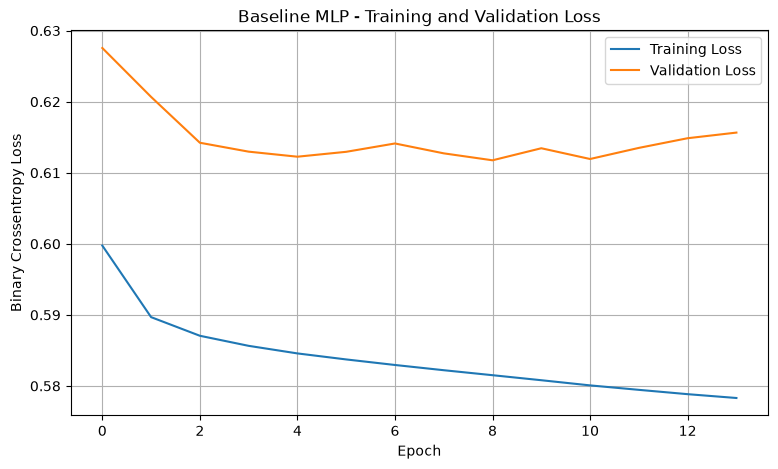

In [30]:
## Baseline MLP loss curve
plt.figure(figsize=(9, 5))

plt.plot(
    baseline_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    baseline_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Baseline MLP - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Crossentropy Loss")
plt.legend()
plt.grid(True)

plt.show()

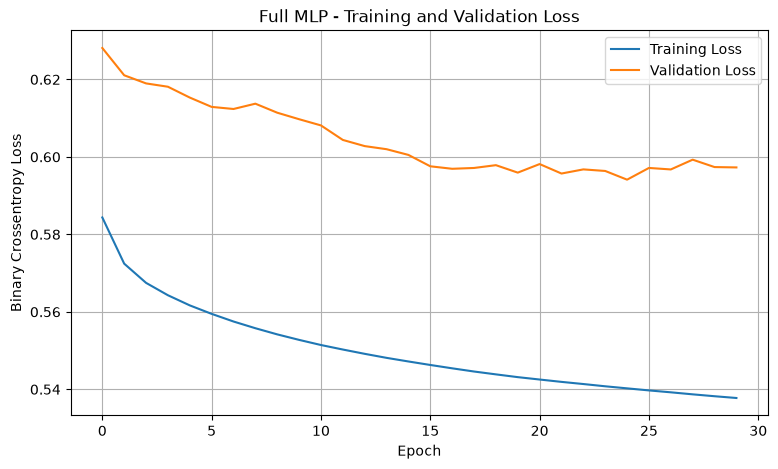

In [31]:
## All eligible columns model loss curve
plt.figure(figsize=(9, 5))

plt.plot(
    full_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    full_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Full MLP - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Crossentropy Loss")
plt.legend()
plt.grid(True)

plt.show()


## Traditional Machine Learning Models

Students must implement at least two traditional machine learning models for comparison with the MLP.
Possible algorithms include:

• Logistic Regression or Linear Regression, depending on the task.
• Decision Tree.
• Random Forest.
• Support Vector Machine (SVM).
• K-Nearest Neighbors (KNN)

### Logistic Regression Model

In [32]:
## Create logistic regression model

# Create model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
logistic_model.fit(
    X_train_balanced,
    y_train_balanced
)

print("Logistic Regression model trained successfully")

Logistic Regression model trained successfully


In [33]:
## Evaluate logistic regression model

# Generate predictions
logistic_predictions = logistic_model.predict(X_test)

# Calculate metrics
logistic_accuracy = accuracy_score(
    y_test, logistic_predictions
)

logistic_precision = precision_score(
    y_test, logistic_predictions,
    zero_division=0
)

logistic_recall = recall_score(
    y_test, logistic_predictions,
    zero_division=0
)

logistic_f1 = f1_score(
    y_test, logistic_predictions,
    zero_division=0
)

# Display results
print("Logistic Regression Results")
print("---------------------------")
print("Accuracy:", logistic_accuracy)
print("Precision:", logistic_precision)
print("Recall:", logistic_recall)
print("F1-Score:", logistic_f1)

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test, logistic_predictions,
    zero_division=0
))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test, logistic_predictions
))

Logistic Regression Results
---------------------------
Accuracy: 0.6911730151685247
Precision: 0.2273365349094939
Recall: 0.6917715827338129
F1-Score: 0.3422120891953512

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.69      0.80     33855
           1       0.23      0.69      0.34      4448

    accuracy                           0.69     38303
   macro avg       0.59      0.69      0.57     38303
weighted avg       0.86      0.69      0.75     38303


Confusion Matrix:
[[23397 10458]
 [ 1371  3077]]


### Random Forest Model

In [34]:
## Create random forest model

## Create model
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

## Train model
random_forest_model.fit(
    X_train_balanced,
    y_train_balanced
)

print("Random Forest model trained successfully")

Random Forest model trained successfully


In [35]:
## Evaluate random forest model

## Generate predictions
rf_predictions = random_forest_model.predict(X_test)

## Calculate metrics
rf_accuracy = accuracy_score(
    y_test, rf_predictions
)

rf_precision = precision_score(
    y_test, rf_predictions,
    zero_division=0
)

rf_recall = recall_score(
    y_test, rf_predictions,
    zero_division=0
)

rf_f1 = f1_score(
    y_test, rf_predictions,
    zero_division=0
)

## Display results
print("Random Forest Results")
print("---------------------")
print("Accuracy:", rf_accuracy)
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1-Score:", rf_f1)

## Classification report
print("\nClassification Report:")
print(classification_report(
    y_test, rf_predictions,
    zero_division=0
))

## Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test, rf_predictions
))

Random Forest Results
---------------------
Accuracy: 0.8310315118920188
Precision: 0.3092006033182504
Recall: 0.368705035971223
F1-Score: 0.3363412633305988

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.89      0.90     33855
           1       0.31      0.37      0.34      4448

    accuracy                           0.83     38303
   macro avg       0.61      0.63      0.62     38303
weighted avg       0.84      0.83      0.84     38303


Confusion Matrix:
[[30191  3664]
 [ 2808  1640]]


### SVM Model

In [36]:
## Create SVM model (Linear SVC was used to accomodate the extremely large dataset)

## Create model
svm_model = LinearSVC(
    max_iter=5000,
    random_state=42,
    dual="auto"
)

## Train model
svm_model.fit(
    X_train_balanced,
    y_train_balanced
)

print("SVM model trained successfully!")

SVM model trained successfully!


In [37]:
## Evaluate SVM model

## Generate predictions
svm_predictions = svm_model.predict(X_test)

## Calculate metrics
svm_accuracy = accuracy_score(
    y_test, svm_predictions
)

svm_precision = precision_score(
    y_test, svm_predictions,
    zero_division=0
)

svm_recall = recall_score(
    y_test, svm_predictions,
    zero_division=0
)

svm_f1 = f1_score(
    y_test, svm_predictions,
    zero_division=0
)

## Display results
print("SVM Results")
print("-----------")
print("Accuracy:", svm_accuracy)
print("Precision:", svm_precision)
print("Recall:", svm_recall)
print("F1-Score:", svm_f1)

## Classification report
print("\nClassification Report:")
print(classification_report(
    y_test, svm_predictions,
    zero_division=0
))

## Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test, svm_predictions
))

SVM Results
-----------
Accuracy: 0.6887972221497011
Precision: 0.22613986219029467
Recall: 0.6935701438848921
F1-Score: 0.3410724156992814

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.69      0.80     33855
           1       0.23      0.69      0.34      4448

    accuracy                           0.69     38303
   macro avg       0.59      0.69      0.57     38303
weighted avg       0.86      0.69      0.74     38303


Confusion Matrix:
[[23298 10557]
 [ 1363  3085]]


### Compare Traditional Models

In [38]:
## Compare traditional models

traditional_ml_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": logistic_accuracy,
        "Precision": logistic_precision,
        "Recall": logistic_recall,
        "F1-Score": logistic_f1
    },
    {
        "Model": "Random Forest",
        "Accuracy": rf_accuracy,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1-Score": rf_f1
    },
    {
        "Model": "SVM",
        "Accuracy": svm_accuracy,
        "Precision": svm_precision,
        "Recall": svm_recall,
        "F1-Score": svm_f1
    }
])

traditional_ml_results

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.691173,0.227337,0.691772,0.342212
1,Random Forest,0.831032,0.309201,0.368705,0.336341
2,SVM,0.688797,0.226140,0.693570,0.341072


## Model Evaluation and Comparison

• Accuracy.
• Precision.
• Recall.
• F1-score.
• Confusion matrix.

Students must present a comparison table showing the performance of all models on the same
held-out test set.

The analysis should address:
1. Which model performed best?
2. Did feature selection improve model performance?
3. Did the MLP outperform traditional machine learning models?

### All Models Comparison

In [39]:
## Compare all models

comparison_df = pd.DataFrame([
    {
        "Model": "Baseline MLP (Selected Features)",
        "Input Features": X_train_selected.shape[1],
        "Accuracy": baseline_accuracy,
        "Precision": baseline_precision,
        "Recall": baseline_recall,
        "F1-Score": baseline_f1
    },
    {
        "Model": "Full MLP (All Features)",
        "Input Features": X_train_full.shape[1],
        "Accuracy": full_accuracy,
        "Precision": full_precision,
        "Recall": full_recall,
        "F1-Score": full_f1
    },
    {
        "Model": "Logistic Regression",
        "Input Features": X_train_balanced.shape[1],
        "Accuracy": logistic_accuracy,
        "Precision": logistic_precision,
        "Recall": logistic_recall,
        "F1-Score": logistic_f1
    },
    {
        "Model": "Random Forest",
        "Input Features": X_train_balanced.shape[1],
        "Accuracy": rf_accuracy,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1-Score": rf_f1
    },
    {
        "Model": "SVM",
        "Input Features": X_train_balanced.shape[1],
        "Accuracy": svm_accuracy,
        "Precision": svm_precision,
        "Recall": svm_recall,
        "F1-Score": svm_f1
    }
])

comparison_df
comparison_df.style.format({
    'Accuracy': '{:.2%}',
    'Precision': '{:.2%}',
    'Recall': '{:.2%}',
    'F1-Score': '{:.2%}'
})

comparison_df

,Model,Input Features,Accuracy,Precision,Recall,F1-Score
0,Baseline MLP (Selected Features),15,0.650080,0.204670,0.697617,0.316487
1,Full MLP (All Features),28,0.676657,0.215947,0.678282,0.327597
2,Logistic Regression,28,0.691173,0.227337,0.691772,0.342212
3,Random Forest,28,0.831032,0.309201,0.368705,0.336341
4,SVM,28,0.688797,0.226140,0.693570,0.341072


### Find Optimized Logistic Regression Hyperparameters

In [40]:
## Optimized Logistic Regression Model

# Define cross-validation strategy
cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Define hyperparameter search space
logistic_param_grid = {
    "C": loguniform(0.001, 100),
    "penalty": ["l1", "l2"],
    "class_weight": ["balanced", None]
}

# Create base Logistic Regression model
logistic_base = LogisticRegression(
    solver="saga",
    max_iter=3000,
    random_state=42,
    tol=0.001
)

# Set up randomized hyperparameter search
logistic_search = RandomizedSearchCV(
    estimator=logistic_base,
    param_distributions=logistic_param_grid,
    n_iter=50,                  # Increase search iterations
    scoring="recall",           # Prioritize identifying positive cases
    cv=cv_strategy,             # Stratified cross-validation
    random_state=42,
    n_jobs=-1,                  # Use all available CPU cores
    verbose=1,
    refit=True,
    return_train_score=True     # Compare training and CV performance
)

# Train and optimize using original training data
logistic_search.fit(
    X_train,
    y_train
)

# Display best parameters
print("Best Logistic Regression Parameters:")
print(logistic_search.best_params_)

print("\nBest Cross-Validation Recall:")
print(logistic_search.best_score_)

# Save optimized model
optimized_logistic = logistic_search.best_estimator_

print("\nOptimized Logistic Regression trained successfully!")

Fitting 3 folds for each of 50 candidates, totalling 150 fits


C:\Users\DylanFerris\anaconda3\envs\tf_project\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\DylanFerris\anaconda3\envs\tf_project\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Best Logistic Regression Parameters:
{'C': np.float64(0.008111941985431923), 'class_weight': 'balanced', 'penalty': 'l1'}

Best Cross-Validation Recall:
0.6880088644794528

Optimized Logistic Regression trained successfully!


In [41]:
## Evaluate Optimized Logistic Regression on Testing Data

# Generate predictions
optimized_logistic_predictions = optimized_logistic.predict(X_test)

# Calculate metrics
optimized_logistic_accuracy = accuracy_score(
    y_test, optimized_logistic_predictions
)

optimized_logistic_precision = precision_score(
    y_test, optimized_logistic_predictions,
    zero_division=0
)

optimized_logistic_recall = recall_score(
    y_test, optimized_logistic_predictions,
    zero_division=0
)

optimized_logistic_f1 = f1_score(
    y_test, optimized_logistic_predictions,
    zero_division=0
)

# Display results
print("Optimized Logistic Regression Results")
print("-------------------------------------")
print("Accuracy:", optimized_logistic_accuracy)
print("Precision:", optimized_logistic_precision)
print("Recall:", optimized_logistic_recall)
print("F1-Score:", optimized_logistic_f1)

print("\nClassification Report:")
print(classification_report(
    y_test,
    optimized_logistic_predictions,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    optimized_logistic_predictions
))

Optimized Logistic Regression Results
-------------------------------------
Accuracy: 0.6808082917787118
Precision: 0.22339971550497867
Recall: 0.706160071942446
F1-Score: 0.3394207910092933

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.68      0.79     33855
           1       0.22      0.71      0.34      4448

    accuracy                           0.68     38303
   macro avg       0.58      0.69      0.56     38303
weighted avg       0.86      0.68      0.74     38303


Confusion Matrix:
[[22936 10919]
 [ 1307  3141]]


### Compare Optimized and Non-Optimized

In [42]:
## Compare Optimized vs. Non-Optimized Logistic Regression

# Create comparison table
logistic_comparison = pd.DataFrame([
    {
        "Model": "Non-Optimized Logistic Regression",
        "Accuracy": logistic_accuracy,
        "Precision": logistic_precision,
        "Recall": logistic_recall,
        "F1-Score": logistic_f1
    },
    {
        "Model": "Optimized Logistic Regression",
        "Accuracy": optimized_logistic_accuracy,
        "Precision": optimized_logistic_precision,
        "Recall": optimized_logistic_recall,
        "F1-Score": optimized_logistic_f1
    }
])

# Display comparison table
print("Logistic Regression Model Comparison")
print("------------------------------------")
display(logistic_comparison.round(4))

# Calculate the difference between optimized and non-optimized models
metric_changes = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Change": [
        optimized_logistic_accuracy - logistic_accuracy,
        optimized_logistic_precision - logistic_precision,
        optimized_logistic_recall - logistic_recall,
        optimized_logistic_f1 - logistic_f1
    ]
})

print("\nChange After Optimization")
print("-------------------------")
display(metric_changes.round(4))

# Display optimized hyperparameters
print("\nBest Optimized Hyperparameters:")
print(logistic_search.best_params_)

Logistic Regression Model Comparison
------------------------------------


,Model,Accuracy,Precision,Recall,F1-Score
0,Non-Optimized Logistic Regression,0.6912,0.2273,0.6918,0.3422
1,Optimized Logistic Regression,0.6808,0.2234,0.7062,0.3394



Change After Optimization
-------------------------


,Metric,Change
0,Accuracy,-0.0104
1,Precision,-0.0039
2,Recall,0.0144
3,F1-Score,-0.0028



Best Optimized Hyperparameters:
{'C': np.float64(0.008111941985431923), 'class_weight': 'balanced', 'penalty': 'l1'}
